### Desafío 6 - Identificación de escenarios naturales del mundo

- Nombre: Jose Ignacio Kuoman Jimenez
- Generacion: G76

### Descripción

En esta oportunidad buscaremos entrenar redes neuronales convolucionales para un conjunto de imágenes que corresponden a escenarios naturales del mundo, con seis diferentes clases:

- **buildings**: Para escenarios con edificios  
- **forest**: Escenarios de bosques  
- **glacier**: Glaciares  
- **mountain**: Escenarios con montañas  
- **sea**: Imágenes con mar  
- **street**: Escenarios de ciudad  

La base de datos se encuentra en cinco archivos serializados (*pickle*):

- **cnn_train_X.npy**: Imágenes destinadas para entrenar los modelos  
- **cnn_train_y.npy**: Etiquetas asociadas a las imágenes de entrenamiento  
- **cnn_test_X.npy**: Imágenes para test  
- **cnn_test_y.npy**: Etiquetas correspondientes a las imágenes de test  
- **cnn_pred_X.npy**: Conjunto de imágenes sin etiquetar destinadas a predicción.

In [2]:
# Para el preprocesamiento de los datos y visualización de los datos
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

In [21]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import KFold

In [58]:
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Flatten, Conv2D, MaxPooling2D, Dropout
from keras.constraints import MaxNorm
from keras.optimizers import SGD
from keras.initializers import HeNormal, GlorotNormal, GlorotUniform
from keras.regularizers import l1, l2, l1_l2
from keras.layers import Dropout
from keras.layers import BatchNormalization

In [59]:
from tensorflow.keras.utils import to_categorical

In [62]:
from tensorflow.keras.callbacks import EarlyStopping

#### Pregunta 1

1. Importa correctamente los conjuntos de datos, desplegando la cantidad de registros de cada categoría para cada conjunto. Despliega ocho imágenes aleatorias del conjunto de entrenamiento y codifica las etiquetas con OneHotEncoder para los conjuntos de entrenamiento y Test.

In [204]:
X_train = np.load('cnn_train_X.npy', allow_pickle=True)
y_train = np.load('cnn_train_y.npy', allow_pickle=True)
X_test = np.load('cnn_test_X.npy', allow_pickle=True)
y_test = np.load('cnn_test_y.npy', allow_pickle=True)
X_pred = np.load('cnn_pred_X.npy', allow_pickle=True)

##### Desplegamos la cantidad de registros de cada categoría para cada conjunto

In [36]:
print('='*20 + '\n')
print('{:<12}{:>5}'.format('X_train', X_train.shape[0]))
print()
print(pd.Series(y_train).value_counts())
print('-'*20 + '\n')

print('{:<12}{:>5}'.format('X_test', X_test.shape[0]))
print()
print(pd.Series(y_test).value_counts())
print('-'*20 + '\n')

print('{:<12}{:>5}'.format('X_pred', X_pred.shape[0]))
print('-'*20)

print('\n'+'='*20)


X_train     14034

mountain     2512
glacier      2404
street       2382
sea          2274
forest       2271
buildings    2191
Name: count, dtype: int64
--------------------

X_test       3000

glacier      553
mountain     525
sea          510
street       501
forest       474
buildings    437
Name: count, dtype: int64
--------------------

X_pred       7301
--------------------



##### Desplegamos ocho imágenes aleatorias del conjunto de entrenamiento

In [38]:
def show_images(X_img, y_img, nrow=3, ncol=3):
    fig, ax = plt.subplots(nrows=nrow, ncols=ncol, figsize=(4 + ncol, 4 + nrow/2.5),
                          sharex=True, sharey=True)

    for i in range(nrow):
        for j in range(ncol):
            alea = np.random.randint(0, X_img.shape[0]+1)
            #print(alea)
            ax[i, j].set_title(y_img[alea])
            ax[i, j].imshow(X_img[alea])
            ax[i, j].set_title(y_img[alea])
            ax[i, j].set_axis_off()
    plt.tight_layout()
    plt.show();

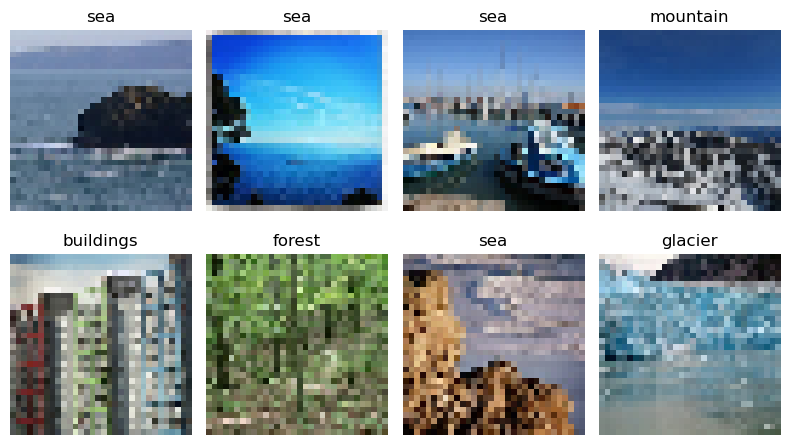

In [190]:
show_images(X_train, y_train, nrow=2, ncol=4)

##### Codificamos las etiquetas con OneHotEncoder para los conjuntos de entrenamiento y Test.

Este codigo tiene un problema `.fit_transform` en la segunda linea debido a que al usar `fit_transform()` en ambos conjuntos por separado, podrías crear codificaciones diferentes para las mismas clases.

```python
one_hot = OneHotEncoder()
y_train = one_hot.fit_transform(y_train.reshape(-1, 1)).toarray()
y_test = one_hot.fit_transform(y_test.reshape(-1, 1)).toarray()
```

In [198]:
print(pd.Series(y_train).value_counts())

mountain     2512
glacier      2404
street       2382
sea          2274
forest       2271
buildings    2191
Name: count, dtype: int64


In [200]:
one_hot = OneHotEncoder(sparse_output=False)             # sparse_output=False reemplaza para que ya no coloques .toarray()
y_train = one_hot.fit_transform(y_train.reshape(-1, 1))  # Aprender y transformar
y_test = one_hot.transform(y_test.reshape(-1, 1))        # Solo transformar

In [202]:
y_train

array([[0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1., 0.]])

In [44]:
y_train[0]

array([0., 1., 0., 0., 0., 0.])

In [46]:
y_train

array([[0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1., 0.]])

In [48]:
y_test[0]

array([0., 1., 0., 0., 0., 0.])

In [50]:
y_test

array([[0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1., 0.]])

#### Pregunta 2

2. Implementa una red neuronal multicapa Fully Connected para clasificar las imágenes, las que deben contener un mínimo de cinco capas ocultas. Despliega las métricas (aplicadas al conjunto de test) que estimes conveniente para medir el rendimiento del modelo.

In [74]:
n_class = y_test.shape[1]
n_class

6

In [89]:
model2 = Sequential()                                                           
model2.add(Input(shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3])))
model2.add(Flatten())
model2.add(Dense(32, activation='relu', use_bias=True, kernel_constraint=MaxNorm(3)))    # 1era capa oculta  
model2.add(Dropout(rate=.2))
model2.add(Dense(64, activation='relu', use_bias=True, kernel_constraint=MaxNorm(3)))    # 2da capa oculta
model2.add(Dropout(rate=.2))
model2.add(Dense(64, activation='relu', use_bias=True, kernel_constraint=MaxNorm(3)))    # 3era capa oculta
model2.add(Dropout(rate=.2))
model2.add(Dense(88, activation='relu', use_bias=True, kernel_constraint=MaxNorm(3)))    # 4ta capa oculta
model2.add(Dropout(rate=.2))
model2.add(Dense(128, activation='relu', use_bias=True, kernel_constraint=MaxNorm(3)))   # 5ta capa oculta
model2.add(Dropout(rate=.2))

# Capa de salida -> units = 6 por la cantidad de clases
model2.add(Dense(units=n_class, activation='softmax', use_bias=True, kernel_constraint=MaxNorm(3))) 

# Compilamos el modelo
model2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)                  │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 32)                  │          98,336 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 88)                  │           5,720 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 88)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 128)                 │          11,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 122,494 (478.49 KB)

 Trainable params: 122,494 (478.49 KB)

 Non-trainable params: 0 (0.00 B)

In [91]:
# Implementamos Early Stopping para detener el entrenamiento cuando no hay mejora
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

epochs = 30
# Entrenamos el modelo
history = model2.fit(
    X_train, y_train,
    batch_size=100,
    epochs=epochs,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping]
)

score = model2.evaluate(X_test, y_test, verbose=0)
print(f'\nTest accuracy: {score[1]}')

Epoch 1/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.2590 - loss: 1.7115 - val_accuracy: 0.4233 - val_loss: 1.4186
Epoch 2/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3931 - loss: 1.4872 - val_accuracy: 0.4393 - val_loss: 1.4263
Epoch 3/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4276 - loss: 1.4376 - val_accuracy: 0.4613 - val_loss: 1.4265
Epoch 4/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4459 - loss: 1.4230 - val_accuracy: 0.4603 - val_loss: 1.4145
Epoch 5/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4559 - loss: 1.3914 - val_accuracy: 0.4633 - val_loss: 1.3821
Epoch 6/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4553 - loss: 1.3893 - val_accuracy: 0.4467 - val_loss: 1.4332
Epoch 7/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4617 - loss: 1.3771 - val_accuracy: 0.4623 - val_loss: 1.4032
Epoch 8/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4675 - loss: 1.3693 - val_accuracy: 0.

In [93]:
yhat_test = model2.predict(X_test)

decoded_y_test = y_test.argmax(axis=1)
decoded_yhat = yhat_test.argmax(axis=1)

print(classification_report(decoded_y_test, decoded_yhat, zero_division=np.nan))

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

           0       0.38      0.42      0.40       437
           1       0.65      0.80      0.72       474
           2       0.55      0.63      0.59       553
           3       0.63      0.53      0.57       525
           4       0.34      0.11      0.17       510
           5       0.50      0.69      0.58       501

    accuracy                           0.53      3000
   macro avg       0.51      0.53      0.50      3000
weighted avg       0.51      0.53      0.50      3000



##### Ojo: Con las capas dropout me sale un accuracy de 0.53

De no haber incluido los dropouts, existiría sobreajuste debido a que la curva de entrenamiento continúa mejorando mientras que la de validación continua empeorando.

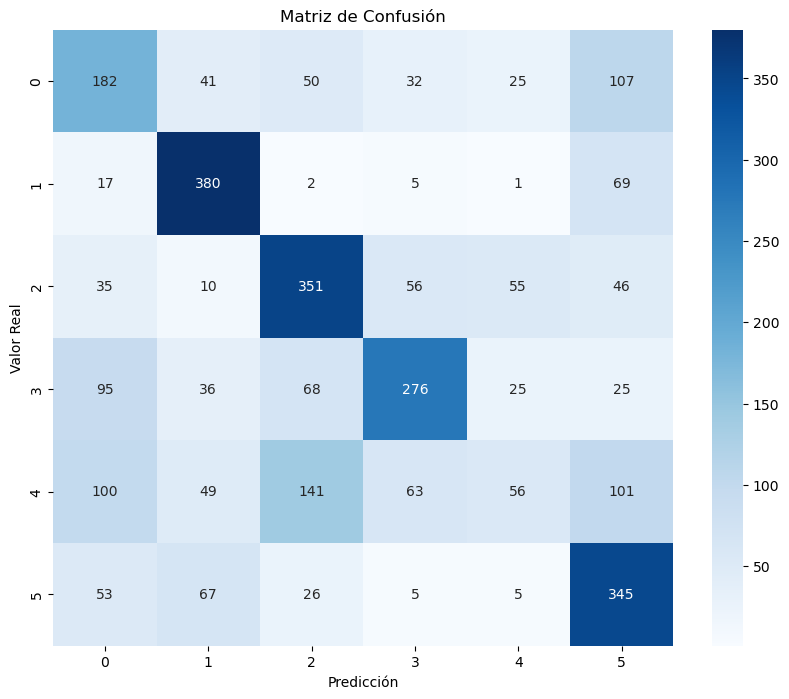

In [95]:
# Matriz de confusion
plt.figure(figsize=(10, 8))
cm = confusion_matrix(decoded_y_test, decoded_yhat)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

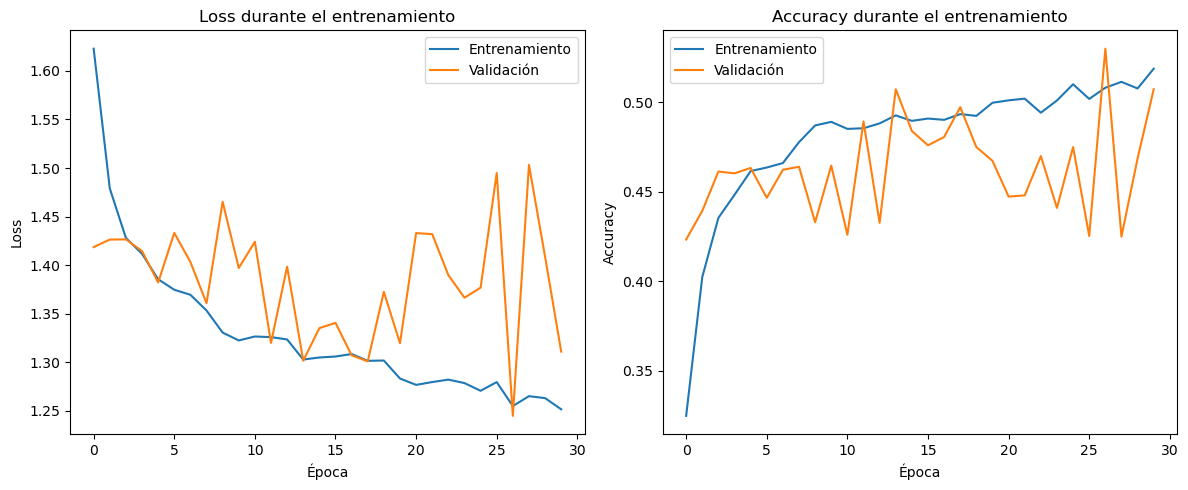

In [97]:
# 3. Gráficos de loss y accuracy durante el entrenamiento
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Loss durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Accuracy durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

#####  <font color ='blue'>No resultó tan buen modelo en cuanto a indicadores dado que no este tipo de redes neuronales no se usan para análisis de imágenes , se ve en la matriz que confunde varias de las categorias entre ellas.</font>

#### Pregunta 3

3. Desarrolla una red neuronal Convolucional usando tres o más capas convolucionales y dos o más capas densas, de manera que la cantidad de parámetros a estimar se encuentre en el intervalo [3MM, 8MM], con 25 épocas. Muestra la curva de la pérdida para cada época y la curva de la métrica accuracy (conjunto test).

In [120]:
n_class = y_test.shape[1]
n_class

6

In [122]:
model3 = Sequential()
model3.add(Input(shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3])))

model3.add(Conv2D(64, (3, 3), activation='relu', padding='same'))                              # 1era capa convolucional
model3.add(BatchNormalization())
model3.add(MaxPooling2D(pool_size=(2, 2)))
model3.add(Dropout(0.2))

model3.add(Conv2D(128, (3, 3), activation='relu', padding='same'))                             # 2da capa convolucional
model3.add(BatchNormalization())
model3.add(MaxPooling2D(pool_size=(2, 2)))
model3.add(Dropout(0.2))

model3.add(Conv2D(256, (3, 3), activation='relu', padding='same'))                             # 3era capa convolucional
model3.add(BatchNormalization())
model3.add(MaxPooling2D(pool_size=(2, 2)))
model3.add(Dropout(0.2))

model3.add(Flatten())

model3.add(Dense(1024, activation='relu', use_bias=True, kernel_constraint=MaxNorm(3)))        # 1era capa densa
model3.add(BatchNormalization())
model3.add(Dropout(0.5))

model3.add(Dense(512, activation='relu', use_bias=True, kernel_constraint=MaxNorm(3)))         # 2da capa densa
model3.add(BatchNormalization())
model3.add(Dropout(0.5))

# Capa de salida
model3.add(Dense(units=n_class, activation='softmax', use_bias=True, kernel_constraint=MaxNorm(3)))

model3.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model3.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 32, 32, 64)          │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 16, 16, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 16, 16, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 8, 8, 256)           │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 8, 8, 256)           │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 4, 4, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_12 (Dropout)                 │ (None, 4, 4, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 4096)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_21 (Dense)                     │ (None, 1024)                │       4,195,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 1024)                │           4,096 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_13 (Dropout)                 │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_22 (Dense)                     │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_14 (Dropout)                 │ (None, 512)                 │              

 Total params: 5,101,958 (19.46 MB)

 Trainable params: 5,097,990 (19.45 MB)

 Non-trainable params: 3,968 (15.50 KB)

In [124]:
# Verifica que el número de parámetros esté entre 3MM y 8MM
total_params = model3.count_params()
print(f"\nTotal de parámetros: {total_params:,}")
assert 3_000_000 <= total_params <= 8_000_000, f"El número de parámetros ({total_params:,}) está fuera del rango [3MM, 8MM]"



Total de parámetros: 5,101,958


In [126]:
# Implementamos Early Stopping para detener el entrenamiento cuando no hay mejora
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

epochs = 25
# Entrenamos el modelo
history = model3.fit(
    X_train, y_train,
    batch_size=64,
    epochs=epochs,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping]
)

score = model3.evaluate(X_test, y_test, verbose=0)
print(f'Test accuracy: {score[1]:.4f}')

Epoch 1/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 22s 84ms/step - accuracy: 0.5153 - loss: 1.6084 - val_accuracy: 0.1777 - val_loss: 4.6335
Epoch 2/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 18s 82ms/step - accuracy: 0.7148 - loss: 0.8072 - val_accuracy: 0.4440 - val_loss: 2.4227
Epoch 3/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 18s 83ms/step - accuracy: 0.7600 - loss: 0.6599 - val_accuracy: 0.6840 - val_loss: 1.1082
Epoch 4/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 18s 83ms/step - accuracy: 0.7898 - loss: 0.5926 - val_accuracy: 0.6190 - val_loss: 1.4071
Epoch 5/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 19s 88ms/step - accuracy: 0.8030 - loss: 0.5440 - val_accuracy: 0.7303 - val_loss: 0.7881
Epoch 6/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 19s 87ms/step - accuracy: 0.8192 - loss: 0.4960 - val_accuracy: 0.6693 - val_loss: 1.3213
Epoch 7/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 19s 88ms/step - accuracy: 0.8267 - loss: 0.4677 - val_accuracy: 0.7333 - val_loss: 0.7787
Epoch 8/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 20s 90ms/step - accuracy: 0.8434 - loss: 0.4377 - 

In [128]:
# Generar predicciones y reporte de clasificación
yhat_test = model3.predict(X_test)

decoded_y_test = y_test.argmax(axis=1)
decoded_yhat = yhat_test.argmax(axis=1)

print(classification_report(decoded_y_test, decoded_yhat, zero_division=np.nan))

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step
              precision    recall  f1-score   support

           0       0.86      0.71      0.77       437
           1       0.95      0.96      0.95       474
           2       0.79      0.76      0.78       553
           3       0.74      0.85      0.79       525
           4       0.84      0.83      0.83       510
           5       0.83      0.87      0.85       501

    accuracy                           0.83      3000
   macro avg       0.84      0.83      0.83      3000
weighted avg       0.83      0.83      0.83      3000



In [130]:
# Realizar predicciones en X_pred
predictions = model3.predict(X_pred)
predicted_classes = np.argmax(predictions, axis=1)
print("Primeras 10 predicciones para X_pred:", predicted_classes[:10])

229/229 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step
Primeras 10 predicciones para X_pred: [4 3 2 1 0 1 2 1 4 4]


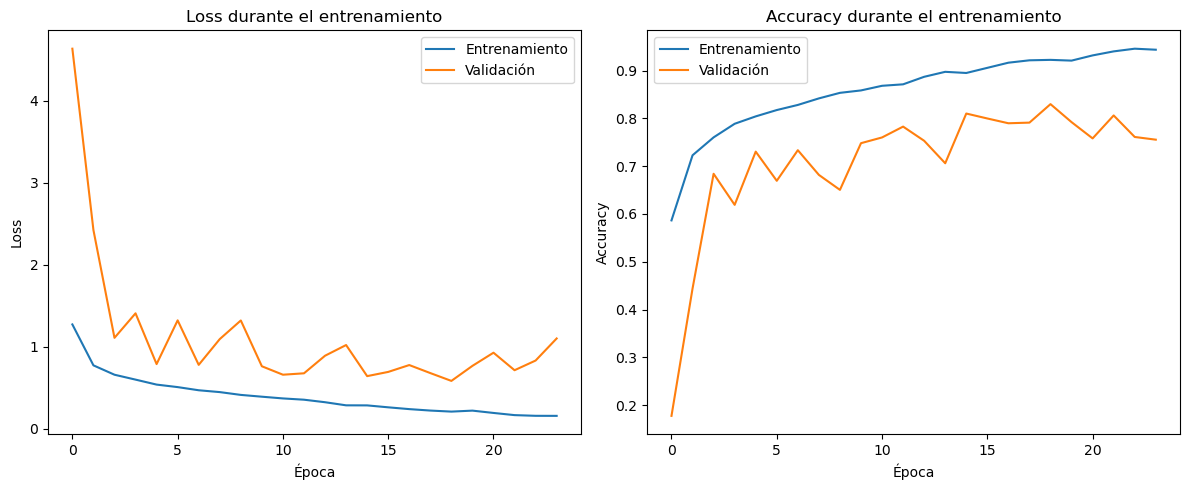

In [132]:
# Gráficos de loss y accuracy durante el entrenamiento
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Loss durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Accuracy durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.savefig('entrenamiento_cnn_results.png')
plt.show()

#### Pregunta 4

4. Implementa una red neuronal Convolucional que mejore la capacidad de generalización alcanzada en el modelo anterior. Para esto usa 16 o más capas (entre convolucionales y densas) y mide su rendimiento.

    Luego, con el modelo entrenado, aplícalo sobre el conjunto de predicción, mide su rendimiento y compáralo con el rendimiento calculado en el modelo anterior. ¿Para qué etiqueta el modelo se equivoca más? Muestra en forma aleatoria ocho imágenes con la etiqueta de predicción otorgada por el modelo.

##### Capas Convolucionales (12 en total):

- Conv2D(64) - Primer bloque, primera capa
- Conv2D(64) - Primer bloque, segunda capa
- Conv2D(128) - Segundo bloque, primera capa
- Conv2D(128) - Segundo bloque, segunda capa
- Conv2D(256) - Tercer bloque, primera capa
- Conv2D(256) - Tercer bloque, segunda capa
- Conv2D(256) - Tercer bloque, tercera capa
- Conv2D(256) - Tercer bloque, cuarta capa
- Conv2D(512) - Cuarto bloque, primera capa
- Conv2D(512) - Cuarto bloque, segunda capa
- Conv2D(512) - Cuarto bloque, tercera capa
- Conv2D(512) - Cuarto bloque, cuarta capa (añadida)

##### Capas Densas (4 en total, sin contar la capa de salida):

- Dense(1024) - Primera capa densa
- Dense(512) - Segunda capa densa
- Dense(256) - Tercera capa densa
- Dense(128) - Cuarta capa densa

##### Capa de Salida (no contada para el requisito):

- Dense(n_class) con activación softmax

En total, el modelo ahora tiene 16 capas entre convolucionales y densas, sin contar la capa de salida, cumpliendo así con el requisito especificado.

In [135]:
# Crear el modelo profundo con al menos 16 capas
model_deep = Sequential(name="Deep_CNN_16plus_layers")

# Capa de entrada
model_deep.add(Input(shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3])))

# Primer bloque convolucional (2 capas)
model_deep.add(Conv2D(64, (3, 3), activation='relu', padding='same'))                            # 1era capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(Conv2D(64, (3, 3), activation='relu', padding='same'))                            # 2da capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(MaxPooling2D(pool_size=(2, 2)))
model_deep.add(Dropout(0.2))

# Segundo bloque convolucional (2 capas)
model_deep.add(Conv2D(128, (3, 3), activation='relu', padding='same'))                           # 3ra capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(Conv2D(128, (3, 3), activation='relu', padding='same'))                           # 4ta capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(MaxPooling2D(pool_size=(2, 2)))
model_deep.add(Dropout(0.2))

# Tercer bloque convolucional (4 capas)
model_deep.add(Conv2D(256, (3, 3), activation='relu', padding='same'))                           # 5ta capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(Conv2D(256, (3, 3), activation='relu', padding='same'))                           # 6ta capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(Conv2D(256, (3, 3), activation='relu', padding='same'))                           # 7ma capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(Conv2D(256, (3, 3), activation='relu', padding='same'))                           # 8va capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(MaxPooling2D(pool_size=(2, 2)))
model_deep.add(Dropout(0.3))

# Cuarto bloque convolucional (4 capas)
model_deep.add(Conv2D(512, (3, 3), activation='relu', padding='same'))                           # 9na capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(Conv2D(512, (3, 3), activation='relu', padding='same'))                           # 10ma capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(Conv2D(512, (3, 3), activation='relu', padding='same'))                           # 11va capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(Conv2D(512, (3, 3), activation='relu', padding='same'))                           # 12va capa convolucional
model_deep.add(BatchNormalization())
model_deep.add(MaxPooling2D(pool_size=(2, 2)))
model_deep.add(Dropout(0.4))

# Aplanar para las capas densas
model_deep.add(Flatten())

# Capas densas (3 capas)
model_deep.add(Dense(1024, activation='relu', kernel_constraint=MaxNorm(3)))
model_deep.add(BatchNormalization())
model_deep.add(Dropout(0.5))

model_deep.add(Dense(512, activation='relu', kernel_constraint=MaxNorm(3)))
model_deep.add(BatchNormalization())
model_deep.add(Dropout(0.5))

model_deep.add(Dense(256, activation='relu', kernel_constraint=MaxNorm(3)))
model_deep.add(BatchNormalization())
model_deep.add(Dropout(0.5))

model_deep.add(Dense(128, activation='relu', kernel_constraint=MaxNorm(3)))
model_deep.add(BatchNormalization())
model_deep.add(Dropout(0.5))

# Capa de salida
model_deep.add(Dense(units=n_class, activation='softmax', kernel_constraint=MaxNorm(3)))

# Compilar el modelo
model_deep.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Mostrar resumen del modelo y contar las capas
model_deep.summary()

Model: "Deep_CNN_16plus_layers"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)                    │ (None, 32, 32, 64)          │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 32, 32, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_6                │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_15 (Dropout)                 │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 16, 16, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_7                │ (None, 16, 16, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 16, 16, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_8                │ (None, 16, 16, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_16 (Dropout)                 │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 8, 8, 256)           │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_9                │ (None, 8, 8, 256)           │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 8, 8, 256)           │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_10               │ (None, 8, 8, 256)           │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_12 (Conv2D)                   │ (None, 8, 8, 256)           │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 8, 8, 256)           │           1,024 │
│ (BatchNormalization)                 │                             │              

 Total params: 13,394,630 (51.10 MB)

 Trainable params: 13,383,878 (51.06 MB)

 Non-trainable params: 10,752 (42.00 KB)

##### Ventajas sobre el modelo anterior (model3)

- ***Mayor capacidad de aprendizaje***: Con más capas, el modelo puede aprender representaciones más complejas y jerárquicas de los datos.
- ***Mejor regularización***: El aumento progresivo de dropout ayuda a prevenir el sobreajuste a medida que la red se hace más profunda.
- ***Transferencia de características más eficiente***: Los bloques convolucionales múltiples permiten una mejor extracción y refinamiento de características.
- ***Análisis de errores más detallado***: La matriz de confusión y el análisis por clase permiten identificar dónde falla el modelo con mayor precisión.

##### Comparación con el modelo anterior

Podrás ver la diferencia en precisión entre ambos modelos en los resultados de la ejecución. Normalmente, este modelo profundo debería tener:

- Mayor precisión en el conjunto de prueba
- Mejor generalización en el conjunto de predicción
- Capacidad para aprender características más sutiles

La clase con mayor error se identifica automáticamente en el código y se muestra la precisión para cada categoría, lo que permite un análisis más detallado del rendimiento.
Las visualizaciones finales te mostrarán 8 imágenes aleatorias con sus etiquetas predichas, permitiéndote ver ejemplos concretos del rendimiento del modelo.

In [137]:
# Contar el número de capas
num_layers = len(model_deep.layers)
print(f"\nNúmero total de capas: {num_layers}")


Número total de capas: 46


In [139]:
# Verificar que tenga al menos 16 capas
assert num_layers >= 16, f"El modelo tiene {num_layers} capas, se requieren al menos 16"

In [141]:
# Verificar parámetros
total_params = model_deep.count_params()
print(f"Total de parámetros: {total_params:,}")

Total de parámetros: 13,394,630


In [143]:
# Implementar Early Stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# Entrenar el modelo
epochs = 25
history = model_deep.fit(
    X_train, y_train,
    batch_size=64,
    epochs=epochs,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping]
)

# Evaluar el modelo en el conjunto de prueba
score = model_deep.evaluate(X_test, y_test, verbose=0)
print(f'\nPrecisión en el conjunto de prueba: {score[1]:.4f}')

Epoch 1/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 101s 424ms/step - accuracy: 0.2968 - loss: 2.2675 - val_accuracy: 0.2207 - val_loss: 5.4348
Epoch 2/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 92s 419ms/step - accuracy: 0.5695 - loss: 1.1045 - val_accuracy: 0.4383 - val_loss: 1.4630
Epoch 3/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 141s 415ms/step - accuracy: 0.6711 - loss: 0.9021 - val_accuracy: 0.6803 - val_loss: 0.9908
Epoch 4/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 99s 452ms/step - accuracy: 0.7372 - loss: 0.7749 - val_accuracy: 0.7507 - val_loss: 0.7567
Epoch 5/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 95s 432ms/step - accuracy: 0.7557 - loss: 0.7209 - val_accuracy: 0.6693 - val_loss: 1.1205
Epoch 6/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 103s 469ms/step - accuracy: 0.7738 - loss: 0.6608 - val_accuracy: 0.8053 - val_loss: 0.5613
Epoch 7/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 98s 443ms/step - accuracy: 0.8040 - loss: 0.5939 - val_accuracy: 0.7617 - val_loss: 0.7716
Epoch 8/25
220/220 ━━━━━━━━━━━━━━━━━━━━ 94s 429ms/step - accuracy: 0.8070 - loss

##### Medimos el rendimiento del modelo que hemos realizado, `model_deep`, sobre el conjunto de prueba

In [145]:
# Generar predicciones y reporte de clasificación para el conjunto de prueba
yhat_test = model_deep.predict(X_test)

decoded_y_test = y_test.argmax(axis=1)
decoded_yhat = yhat_test.argmax(axis=1)

print("\nReporte de clasificación en conjunto de prueba:")
print(classification_report(decoded_y_test, decoded_yhat, zero_division=np.nan))

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step

Reporte de clasificación en conjunto de prueba:
              precision    recall  f1-score   support

           0       0.84      0.74      0.78       437
           1       0.91      0.96      0.94       474
           2       0.84      0.64      0.73       553
           3       0.79      0.78      0.78       525
           4       0.68      0.86      0.76       510
           5       0.82      0.88      0.85       501

    accuracy                           0.81      3000
   macro avg       0.81      0.81      0.81      3000
weighted avg       0.81      0.81      0.80      3000



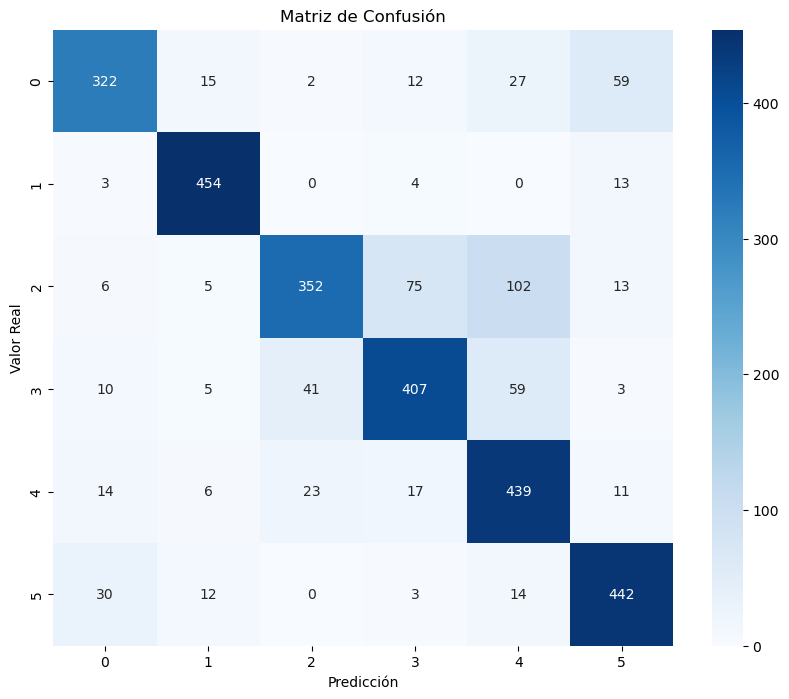

In [147]:
# Matriz de confusión para identificar en qué etiquetas hay más errores
conf_matrix = confusion_matrix(decoded_y_test, decoded_yhat)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.savefig('confusion_matrix.png')
plt.show()

- La diagonal principal muestra las predicciones correctas

##### ¿Para que etiqueta el modelo se equivoca más?

Para calcularlo, como primera instancia calculamos el rendimiento por cada clase

- `conf_matrix.diagonal()`: Extrae los valores de la diagonal principal (predicciones correctas para cada clase)
- `conf_matrix.sum(axis=1)`: Suma cada fila para obtener el total de muestras reales por clase
- La división de estos valores da la precisión (accuracy) para cada clase individual
- Luego se imprime la precisión para cada clase con formato de 4 decimales

In [172]:
conf_matrix.diagonal()

array([322, 454, 352, 407, 439, 442], dtype=int64)

In [174]:
conf_matrix.sum(axis=1)

array([437, 474, 553, 525, 510, 501], dtype=int64)

In [149]:
# Calculamos el rendimiento por clase
class_accuracy = conf_matrix.diagonal() / conf_matrix.sum(axis=1)

print("\nPrecisión por clase:\n")
for i, acc in enumerate(class_accuracy):
    print(f"Clase {i}: {acc:.4f}")

# Identificar la clase con mayor error
worst_class = np.argmin(class_accuracy)
print(f"\nLa clase con mayor error es: {worst_class} con precisión de {class_accuracy[worst_class]:.4f}")


Precisión por clase:
Clase 0: 0.7368
Clase 1: 0.9578
Clase 2: 0.6365
Clase 3: 0.7752
Clase 4: 0.8608
Clase 5: 0.8822

La clase con mayor error es: 2 con precisión de 0.6365


In [177]:
class_accuracy

array([0.73684211, 0.95780591, 0.63652803, 0.7752381 , 0.86078431,
       0.88223553])

##### Con el modelo entrenado, aplicalo sobre el conjunto de predicción

In [151]:
# Realizar predicciones en X_pred
predictions_pred = model_deep.predict(X_pred)
predicted_classes_pred = np.argmax(predictions_pred, axis=1)

# Convertir índices de clases a etiquetas originales
# Asumiendo que tenemos las etiquetas originales en alguna parte
# Si no las tenemos, usamos los índices de clase
pred_labels = predicted_classes_pred  # Reemplazar con la transformación adecuada si es necesario

229/229 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step


In [162]:
predicted_classes_pred

array([5, 3, 2, ..., 4, 5, 3], dtype=int64)

```python
pred_labels_str = [str(label) for label in pred_labels]
```
- Utiliza una comprensión de lista para convertir cada valor numérico en pred_labels a formato string
- `pred_labels` contiene los índices de clase predichos por el modelo (números enteros como 0, 1, 2, etc.)
- Esta conversión es necesaria porque la función show_images está diseñada para trabajar con etiquetas en formato string cuando las muestra como títulos en los subplots

##### Ejemplo:

- Si `pred_labels = [0, 3, 1, 2, 0, 3, 2, 1]` (índices de clases predichas)
- `pred_labels_str` será `["0", "3", "1", "2", "0", "3", "2", "1"]` (strings)

##### Mostramos en forma aleatoria ocho imágenes con la etiqueta de predicción otorgada por el modelo

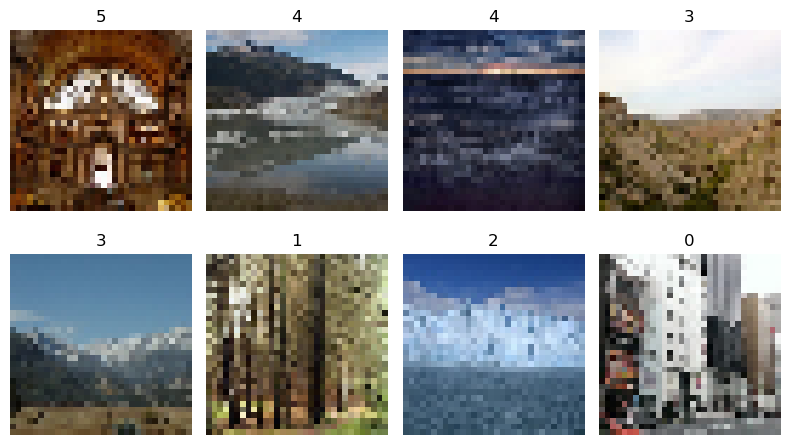

In [153]:
# Convertir etiquetas numéricas a string para la función
pred_labels_str = [str(label) for label in pred_labels]
show_images(X_pred, pred_labels_str, nrow=2, ncol=4)

El método set_title() de matplotlib acepta automáticamente cualquier tipo de datos y los convierte internamente a string utilizando la función str(). Por lo tanto:

- Si pasas un número entero como 3, matplotlib lo convertirá automáticamente a "3"
- Si pasas una lista de números, matplotlib extraerá el elemento correspondiente y lo convertirá a string

Esto significa que el código podría haberse escrito directamente como:

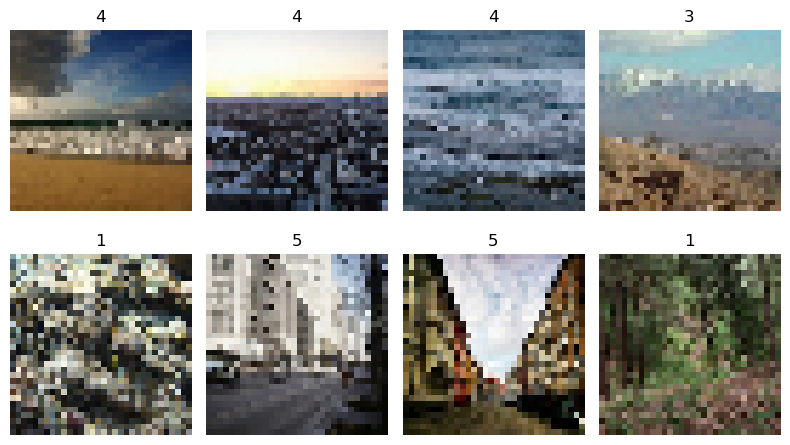

In [181]:
# Pero no es necsario convertir las etiquetas numericas a string
show_images(X_pred, pred_labels, nrow=2, ncol=4)

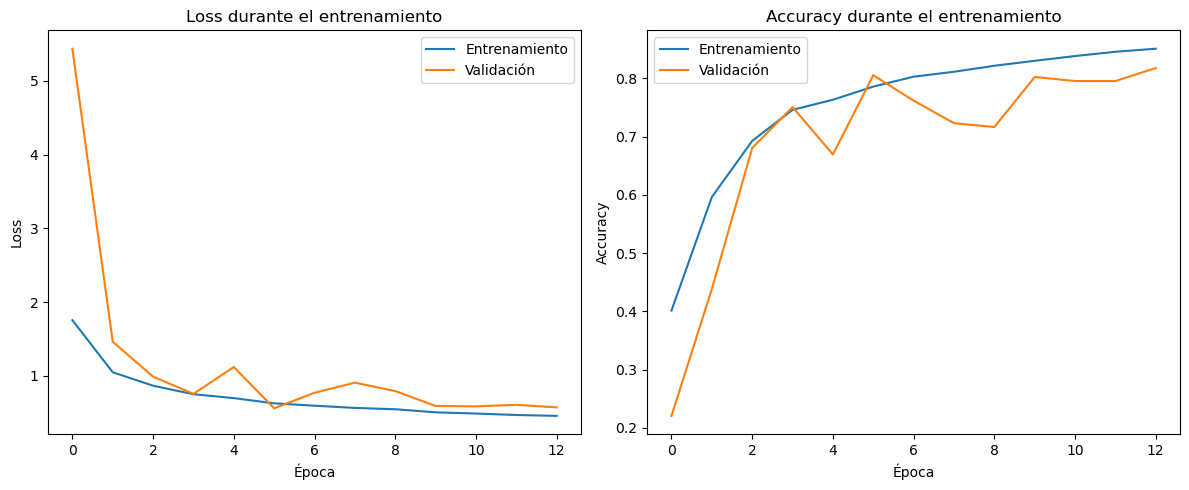

In [155]:
# Gráficos de loss y accuracy durante el entrenamiento
plt.figure(figsize=(12, 5))

# Gráfico de pérdida
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Loss durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

# Gráfico de precisión
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Accuracy durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.savefig('deep_cnn_training.png')
plt.show()

##### Recordar lo siguiente
- ***BatchNormalization*** -> Propósito principal: Estabilizar y acelerar el entrenamiento
- ***MaxPooling2D*** -> Propósito principal: Reducir dimensionalidad espacial y destacar características importantes
- ***Dropout*** -> Propósito principal: Regularización para prevenir el sobreajuste. ***Mejora generalización***: Ayuda a que la red funcione mejor con datos nuevos, no vistos durante el entrenamiento